# Task 1 (Level 1 — Basic): Data Preprocessing for Machine Learning

**Codveda Technologies Machine Learning Internship**

This notebook executes and verifies:
1. Comprehensive schema, checksum, missingness, duplicate, and data-quality audit across all 6 supplied datasets.
2. Leakage-free temporal preprocessing on `2) Stock Prices Data Set.csv` (497,472 rows; 27 genuine raw `NaN` cells across `open`, `high`, `low`; unseen 2017 ticker symbols).
3. Multicollinearity (VIF) remediation and categorical/numerical `ColumnTransformer` pipelines for Customer Churn (`churn-bigml-80/20.csv`) and Iris (`1) iris.csv`).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
from codveda_ml.data.loaders import audit_all_datasets, prepare_stock_supervised_splits, load_churn_splits
from codveda_ml.preprocessing.pipelines import build_stock_preprocessor, build_churn_preprocessor, compute_vif_table
from codveda_ml.data.loaders import CHURN_NUMERIC_COLS_ALL, CHURN_NUMERIC_COLS_PRUNED

inventory_df = audit_all_datasets(ROOT)
display(inventory_df[['dataset_file', 'n_rows', 'n_cols', 'total_missing_cells', 'exact_duplicate_rows', 'assigned_tasks']])

,dataset_file,n_rows,n_cols,total_missing_cells,exact_duplicate_rows,assigned_tasks
0,1) iris.csv,150,5,0,3,"Task 2 (KNN), Task 4 (Decision Tree)"
1,2) Stock Prices Data Set.csv,497472,7,27,0,Task 1 (Data Preprocessing — genuine raw NaNs ...
2,3) Sentiment dataset.csv,732,15,0,0,Audited in Task 1 (not selected for primary su...
3,4) house Prediction Data Set.csv,506,14,0,0,Audited in Task 1 (corresponds to unselected L...
4,Churn Prdiction Data/churn-bigml-80.csv,2666,20,0,0,"Task 1, Task 3 (Logistic Regression), Task 5 (..."
5,Churn Prdiction Data/churn-bigml-20.csv,667,20,0,0,"Task 1, Task 3 (Logistic Regression), Task 5 (..."


## 1.1 Handling Genuine Missing Data & Preventing Temporal Leakage on S&P 500 Stock Prices

In [2]:
stock = prepare_stock_supervised_splits(ROOT, train_end_date='2016-12-31')
print('Train window:', stock['train_dates'], '| rows:', len(stock['X_train']))
print('Test window :', stock['test_dates'],  '| rows:', len(stock['X_test']))
print('Train missing counts:', stock['X_train'][['open','high','low','close','volume']].isna().sum().to_dict())
print('Test missing counts :', stock['X_test'][['open','high','low','close','volume']].isna().sum().to_dict())

stock_pipe = build_stock_preprocessor(imputer_strategy='median', scaler_type='standard', add_missing_indicator=True)
X_tr_tx = stock_pipe.fit_transform(stock['X_train'], stock['y_train'])
X_te_tx = stock_pipe.transform(stock['X_test'])
print('Transformed shapes:', X_tr_tx.shape, X_te_tx.shape)
print('Post-imputation NaNs (train, test):', int(np.isnan(X_tr_tx.data).sum()), int(np.isnan(X_te_tx.data).sum()))

Train window: ('2014-01-02', '2016-12-30') | rows: 371440
Test window : ('2017-01-03', '2017-12-28') | rows: 125527
Train missing counts: {'open': 10, 'high': 7, 'low': 7, 'close': 0, 'volume': 0}
Test missing counts : {'open': 1, 'high': 1, 'low': 1, 'close': 0, 'volume': 0}


Transformed shapes: (371440, 525) (125527, 525)
Post-imputation NaNs (train, test): 0 0


## 1.2 Eliminating Exact Billing Collinearity (VIF > 10,000,000 -> 1.004) in Customer Churn

In [3]:
churn = load_churn_splits(ROOT)
vif_all = compute_vif_table(churn['df_train'][CHURN_NUMERIC_COLS_ALL])
vif_pruned = compute_vif_table(churn['df_train'][CHURN_NUMERIC_COLS_PRUNED])
print('Top 8 VIFs BEFORE dropping redundant *charge columns:')
display(vif_all.head(8))
print('All 11 VIFs AFTER dropping redundant *charge columns:')
display(vif_pruned)

Top 8 VIFs BEFORE dropping redundant *charge columns:


,feature,r_squared_with_others,vif
0,Total day charge,1.000000,1.041073e+07
1,Total day minutes,1.000000,1.041072e+07
2,Total eve charge,1.000000,2.291580e+06
3,Total eve minutes,1.000000,2.291577e+06
4,Total night minutes,0.999998,6.477278e+05
5,Total night charge,0.999998,6.477272e+05
6,Total intl charge,0.999985,6.827899e+04
7,Total intl minutes,0.999985,6.827841e+04


All 11 VIFs AFTER dropping redundant *charge columns:


,feature,r_squared_with_others,vif
0,Total day calls,0.003979,1.004
1,Total intl minutes,0.003351,1.003
2,Account length,0.003103,1.003
3,Total intl calls,0.003371,1.003
4,Number vmail messages,0.001725,1.002
5,Total day minutes,0.001877,1.002
6,Total eve minutes,0.001548,1.002
7,Total night calls,0.002289,1.002
8,Customer service calls,0.001778,1.002
9,Total night minutes,0.000787,1.001


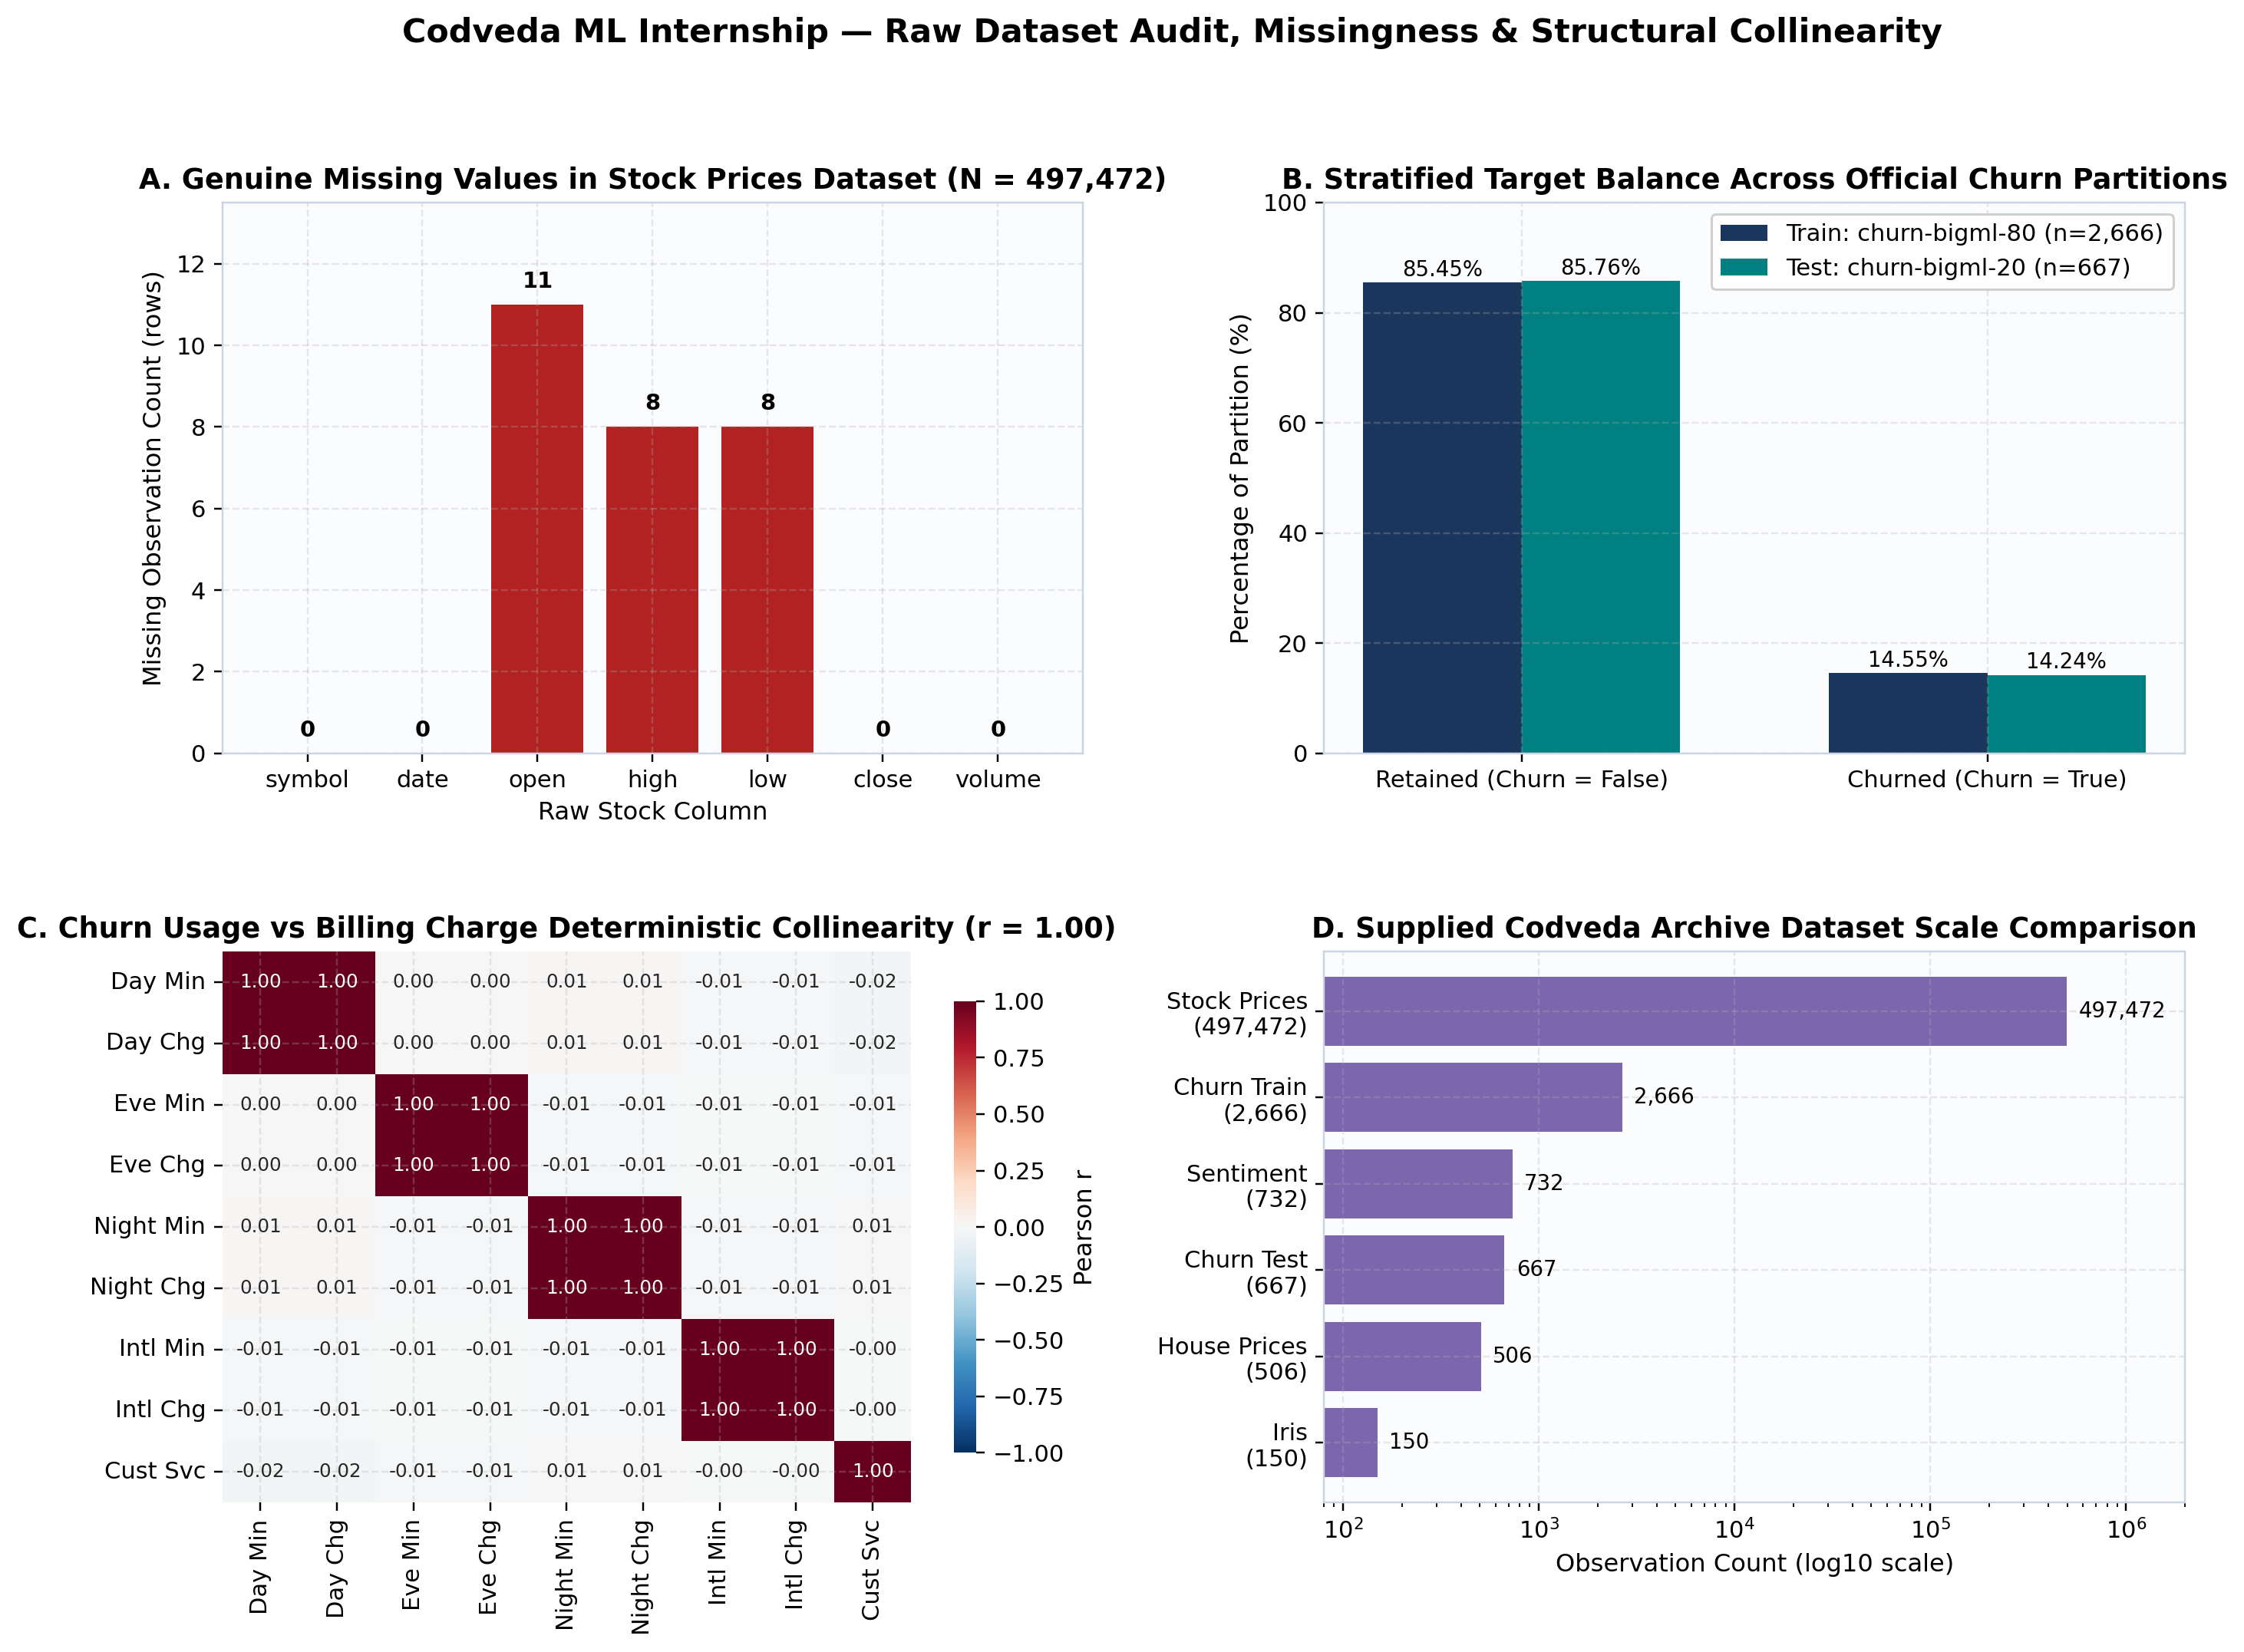

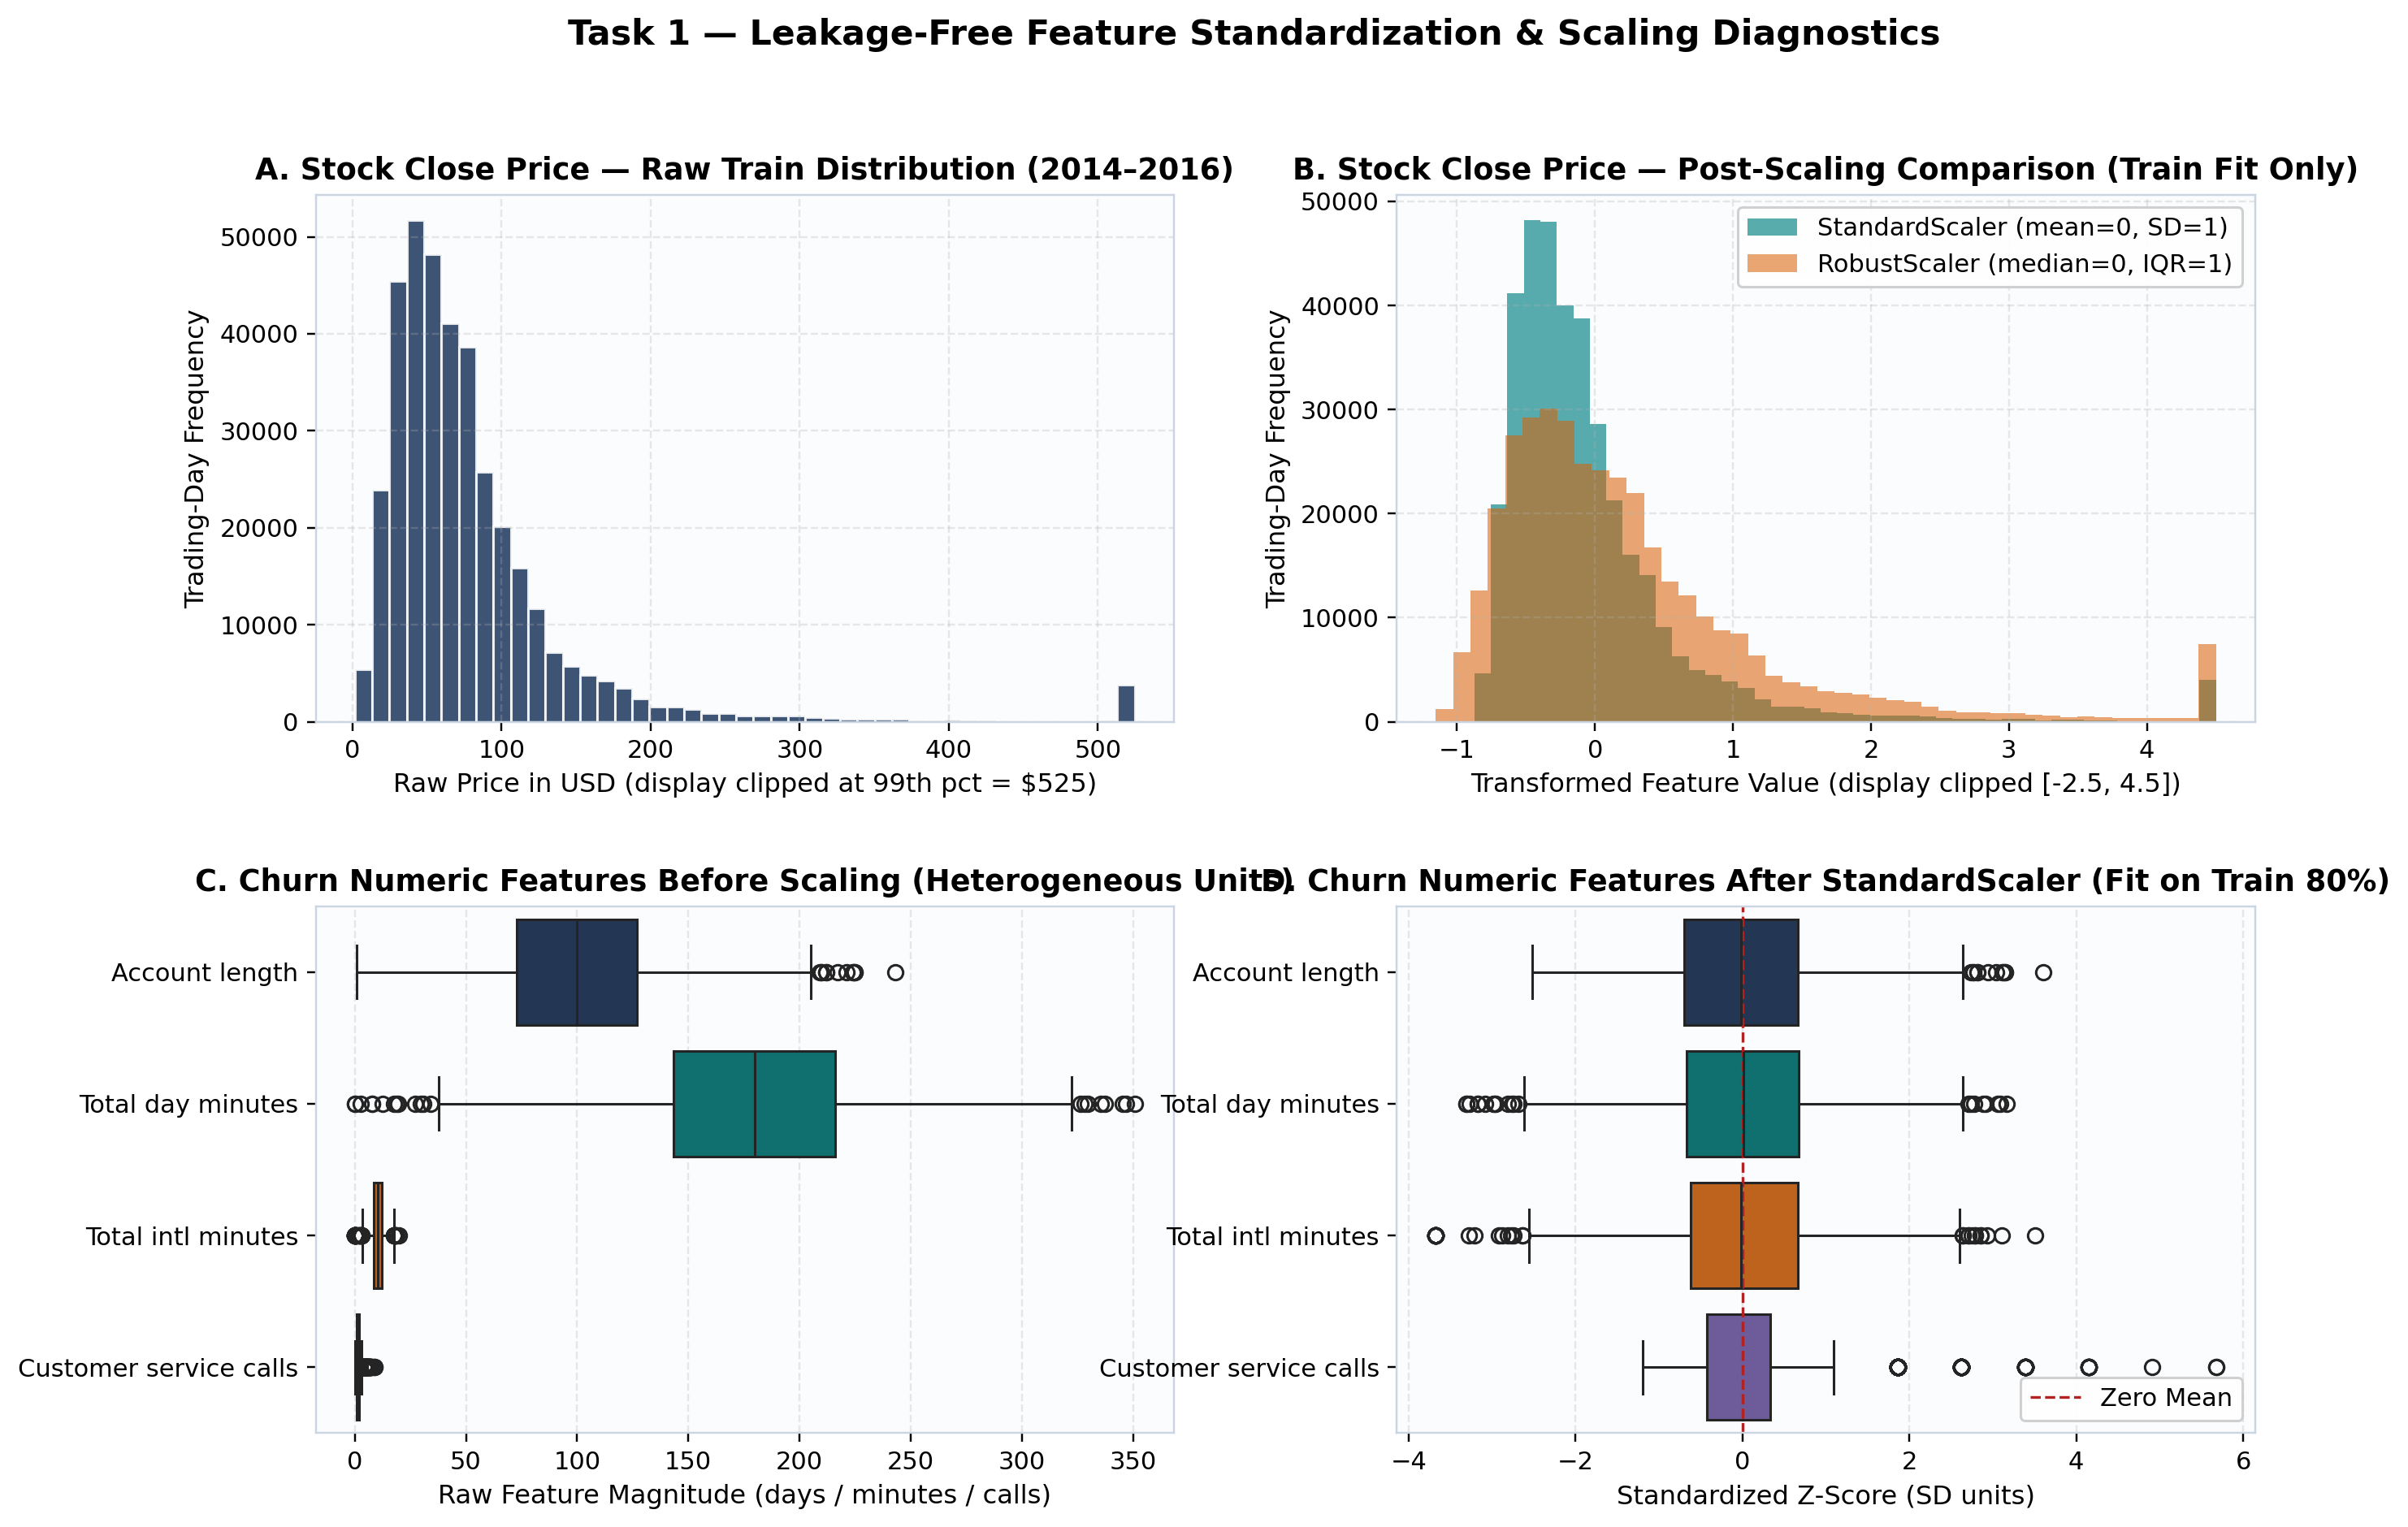

In [4]:
display(Image(filename=str(ROOT / 'results/figures/fig01_dataset_quality_and_missingness_audit.png')))
display(Image(filename=str(ROOT / 'results/figures/fig02_preprocessing_scaling_and_distributions.png')))